# Model Selection and Hyperparameter Tuning

**Use scikit-learn as much as possible!**

In [43]:
import pandas as pd
import numpy as np

## Ames Housing Data

As usual, we'll try to predict SalePrice using a mix of quantitative and categorical features. See the [data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for all the variables that are available in the data set. We'll try to come up with a model that minimizes test error, measured by root mean square error (RMSE).

In [44]:
df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


1\. Recall that in a previous notebook we fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. But what about other sets of features?


I tested five different sets of features using a 10-nearest neighbors regression model. **Set 5 had the lowest RMSE of 30,417.47**, using Gr Liv Area, Overall Qual, Year Built, Total Bsmt SF, Garage Cars, and Neighborhood. This means the model's predictions had a typical error of around $30,417. Since a lower RMSE means better predictions, Set 5 performed the best out of all five sets.

Specify 5 sets of features to investigate. These sets could be subsets of the variables above, but you should also include other variables from the data set. The choice is up to you, but try to guess which sets might lead to good models based on your intuition and what we have already seen for this data set.

For each set of features, fit a 10-nearest neighbors regression model and estimate its test error (RMSE) using cross-validation. You can write a loop to iterate over the sets of features similar to what was done in the Model Selection section of the pre-class notebook.

Report your lowest RMSE and the corresponding features.

In [45]:

# QUESTION 1 - Compare 5 Feature Sets Using KNN

import pandas as pd
import numpy as np

from sklearn.model_selection import cross_val_score, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Define 5 different sets of features
feature_sets = {
    "Set 1": ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"],
    "Set 2": ["Gr Liv Area", "Overall Qual", "Year Built"],
    "Set 3": ["Gr Liv Area", "Overall Qual", "Total Bsmt SF", "Garage Cars"],
    "Set 4": ["Gr Liv Area", "Overall Qual", "Year Built", "Neighborhood", "Garage Cars"],
    "Set 5": ["Gr Liv Area", "Overall Qual", "Year Built", "Total Bsmt SF", "Garage Cars", "Neighborhood"]
}

# Set up cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = {}

# Test each feature set
for name, features in feature_sets.items():

    X = df_ames[features].copy()
    y = df_ames["SalePrice"]

    # Identify numeric and categorical features
    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

    # Handle missing values and scale numeric features
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Handle missing categorical values
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Preprocess features
    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    # Build KNN model with 10 neighbors
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("knn", KNeighborsRegressor(n_neighbors=10))
    ])

    # Calculate cross-validation RMSE
    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        error_score="raise"
    )

    results[name] = -scores.mean()

# Display results
results_df = pd.DataFrame({
    "Feature Set": list(results.keys()),
    "RMSE": list(results.values())
}).sort_values("RMSE")

print(results_df.to_string(index=False))

# Find the best feature set
best_set = results_df.iloc[0]["Feature Set"]
best_features = feature_sets[best_set]

print("\nBest Feature Set:", best_set)
print("Features:", best_features)
print("Lowest RMSE:", round(results[best_set], 2))



Feature Set         RMSE
      Set 5 30417.195486
      Set 3 31470.603942
      Set 4 33030.969991
      Set 2 33895.719407
      Set 1 39297.680635

Best Feature Set: Set 5
Features: ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Total Bsmt SF', 'Garage Cars', 'Neighborhood']
Lowest RMSE: 30417.2


2\. Recall that in a previous notebook we fit a $k$-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Previously we used a loop to iterate and find the value of $k$ with the smallest test error (RMSE).

Now use grid search in scikit-learn to implement this process. Use the results to create a plot of test error versus $k$.

The best number of neighbors was **k = 8**, which gave the lowest RMSE of **38,745.80**. The graph shows that the RMSE decreases as the number of neighbors increases from 1 to 8. After 8 neighbors, the RMSE starts increasing again, meaning the predictions become less accurate. This shows that using 8 neighbors gives the best performance for this model.

Best k: 8
Lowest RMSE: 38745.8


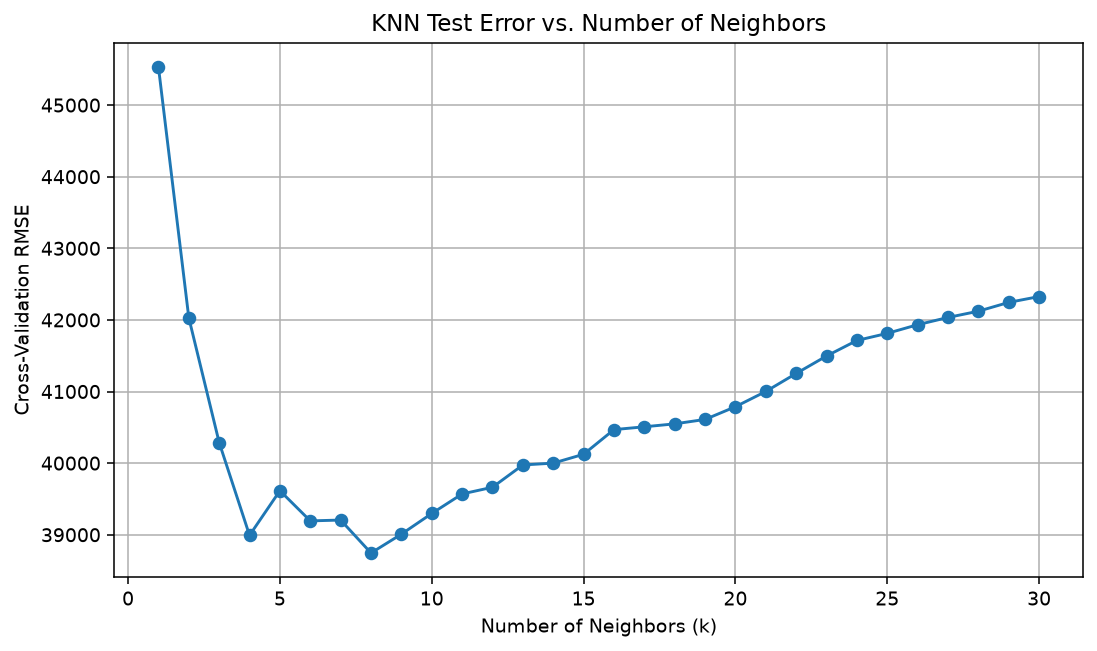

In [46]:

from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

features_q2 = [
    "Gr Liv Area", "Bedroom AbvGr",
    "Full Bath", "Half Bath", "Neighborhood"
]

X = df_ames[features_q2]
y = df_ames["SalePrice"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsRegressor())
])

param_grid = {
    "knn__n_neighbors": range(1, 31)
}

grid_q2 = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

grid_q2.fit(X, y)

print("Best k:", grid_q2.best_params_["knn__n_neighbors"])
print("Lowest RMSE:", round(-grid_q2.best_score_, 2))

results_q2 = pd.DataFrame(grid_q2.cv_results_)

plt.figure(figsize=(9, 5))
plt.plot(
    results_q2["param_knn__n_neighbors"].astype(int),
    -results_q2["mean_test_score"],
    marker="o"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Cross-Validation RMSE")
plt.title("KNN Test Error vs. Number of Neighbors")
plt.grid(True)
plt.show()


3\. $k$-nearest neighbors relies on distance and we know there are different distance metrics. Repeat the previous part and use grid search to iterate over both (1) `n_neighbors` and (2) `metric`, which can be `"euclidean"` or `"manhattan"` (see the the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)). Compare the results to the previous part. (Hint: recall the note in the pre-class notebook about grid search conventions for refering to steps in the pipeline.)

I compared Euclidean and Manhattan distance to see which one gave better predictions. The best model used **Manhattan distance with 8 neighbors**, giving the lowest RMSE of **38,717.75**. This was slightly better than Question 2, which had an RMSE of 38,745.80. The graph shows that Manhattan distance generally performed a little better than Euclidean distance. Overall, changing the distance metric improved the model slightly, but the difference was very small.

Best Parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 8}
Lowest RMSE: 38717.75
Question 2 RMSE: 38745.8


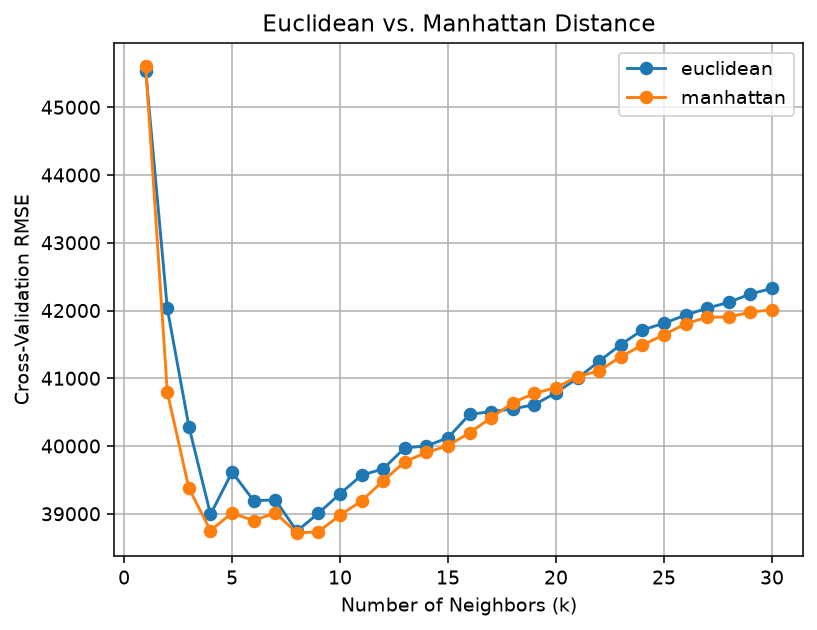

In [47]:

param_grid_q3 = {
    "knn__n_neighbors": range(1, 31),
    "knn__metric": ["euclidean", "manhattan"]
}

grid_q3 = GridSearchCV(
    pipeline,
    param_grid_q3,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

grid_q3.fit(X, y)

print("Best Parameters:", grid_q3.best_params_)
print("Lowest RMSE:", round(-grid_q3.best_score_, 2))
print("Question 2 RMSE:", round(-grid_q2.best_score_, 2))

results_q3 = pd.DataFrame(grid_q3.cv_results_)

for metric in ["euclidean", "manhattan"]:
    subset = results_q3[
        results_q3["param_knn__metric"] == metric
    ]

    plt.plot(
        subset["param_knn__n_neighbors"].astype(int),
        -subset["mean_test_score"],
        marker="o",
        label=metric
    )

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Cross-Validation RMSE")
plt.title("Euclidean vs. Manhattan Distance")
plt.legend()
plt.grid(True)
plt.show()


4\. Combine elements of the previous parts and fit what you think will be the best $k$-nearest neighbors model. Specify which features you are using, the value of $k$, and the distance metric. Estimate the test error. (In 2-3 you used the specified set of features. Now you can combine elements of 2-3 with the features you chose in part 1, or other sets of features, as well as investigating other parameter choices.)

Note: Look at the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) for a full list of parameters. You might consider tuning `n_neighbors`, `metric` (or `p`), and/or `weights`. You could also try other elements like scaling too.

For my best KNN model, I used six features: Gr Liv Area, Overall Qual, Year Built, Total Bsmt SF, Garage Cars, and Neighborhood. The best parameters were **10 neighbors, Euclidean distance, and distance-based weights**. The model had an RMSE of **29,134.41**, which is lower than the RMSE of 30,417.47 from Question 1. This shows that tuning the parameters improved the model's predictions and made them more accurate.

In [48]:

df_ames = df_ames.copy()

for column in df_ames.columns:
    if column == "SalePrice":
        continue
    if pd.api.types.is_numeric_dtype(df_ames[column]):
        df_ames[column] = df_ames[column].fillna(df_ames[column].median())
    else:
        df_ames[column] = df_ames[column].fillna("Missing")


In [49]:

features_q4 = best_features

X_q4 = df_ames[features_q4]
y_q4 = df_ames["SalePrice"]

numeric_q4 = X_q4.select_dtypes(include=np.number).columns.tolist()
categorical_q4 = X_q4.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_q4 = ColumnTransformer([
    ("num", StandardScaler(), numeric_q4),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_q4)
])

pipeline_q4 = Pipeline([
    ("preprocessor", preprocessor_q4),
    ("knn", KNeighborsRegressor())
])

param_grid_q4 = {
    "knn__n_neighbors": [3, 5, 7, 10, 15, 20, 25, 30],
    "knn__metric": ["euclidean", "manhattan"],
    "knn__weights": ["uniform", "distance"]
}

grid_q4 = GridSearchCV(
    pipeline_q4,
    param_grid_q4,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

grid_q4.fit(X_q4, y_q4)

best_knn_rmse = -grid_q4.best_score_

print("Features Used:", features_q4)
print("Best Parameters:", grid_q4.best_params_)
print("Best KNN RMSE:", round(best_knn_rmse, 2))


Features Used: ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Total Bsmt SF', 'Garage Cars', 'Neighborhood']
Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 10, 'knn__weights': 'distance'}
Best KNN RMSE: 29134.41


5\. Now fit a linear regression model using the same features that you used in the previous part. Estimate the test error. How does the test error for linear regression compare to the kNN model?

I compared Linear Regression and KNN using the same six features. Linear Regression had an RMSE of **34,264.37**, while KNN had a lower RMSE of **29,134.41**. This means KNN had a smaller prediction error by about $5,130. Overall, KNN performed better than Linear Regression and was the better model for predicting house prices using these features.

In [50]:

from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("preprocessor", preprocessor_q4),
    ("linear", LinearRegression())
])

linear_scores = cross_val_score(
    linear_model,
    X_q4,
    y_q4,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

linear_rmse = -linear_scores.mean()

print("Linear Regression RMSE:", round(linear_rmse, 2))
print("KNN RMSE:", round(best_knn_rmse, 2))

if linear_rmse < best_knn_rmse:
    print("Linear Regression performed better.")
else:
    print("KNN performed better.")


Linear Regression RMSE: 34264.37
KNN RMSE: 29134.41
KNN performed better.


## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

Note: when you are consider features to include, you might want to consider transformations of the variables.

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [51]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


Explore the data

Dataset Shape: (10000, 56)

Column Names:
['Unnamed: 0', 'emp_title', 'emp_length', 'state', 'homeownership', 'annual_income', 'verified_income', 'debt_to_income', 'annual_income_joint', 'verification_income_joint', 'debt_to_income_joint', 'delinq_2y', 'months_since_last_delinq', 'earliest_credit_line', 'inquiries_last_12m', 'total_credit_lines', 'open_credit_lines', 'total_credit_limit', 'total_credit_utilized', 'num_collections_last_12m', 'num_historical_failed_to_pay', 'months_since_90d_late', 'current_accounts_delinq', 'total_collection_amount_ever', 'current_installment_accounts', 'accounts_opened_24m', 'months_since_last_credit_inquiry', 'num_satisfactory_accounts', 'num_accounts_120d_past_due', 'num_accounts_30d_past_due', 'num_active_debit_accounts', 'total_debit_limit', 'num_total_cc_accounts', 'num_open_cc_accounts', 'num_cc_carrying_balance', 'num_mort_accounts', 'account_never_delinq_percent', 'tax_liens', 'public_record_bankrupt', 'loan_purpose', 'application_type', 'loan_

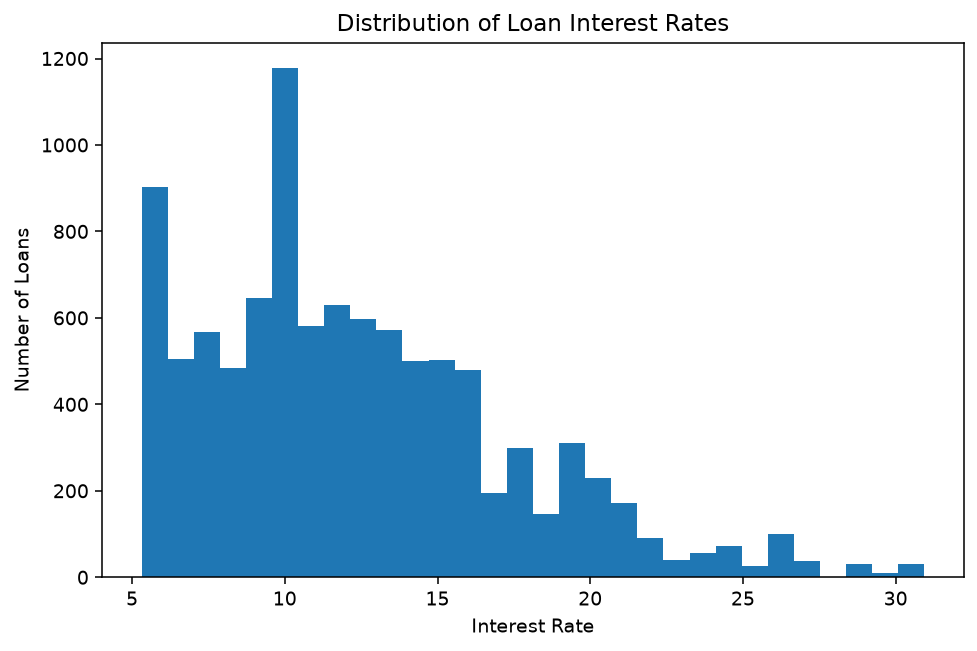

In [52]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
print(df.head())

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

print("\nInterest Rate Summary:")
print(df["interest_rate"].describe())

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["interest_rate"].dropna(), bins=30)
plt.xlabel("Interest Rate")
plt.ylabel("Number of Loans")
plt.title("Distribution of Loan Interest Rates")
plt.show()


This code selects available loan-related variables and handles missing values during model training. It avoids using the interest rate itself as a predictor.

In [53]:

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

loan_features = [
    "loan_amount",
    "term",
    "annual_income",
    "debt_to_income",
    "credit_score",
    "grade",
    "sub_grade",
    "homeownership",
    "verified_income",
    "loan_purpose",
    "state",
    "total_credit_limit",
    "total_credit_utilized",
    "public_record_bankrupt",
    "delinq_2y"
]

loan_features = [c for c in loan_features if c in df.columns]

loans = df.dropna(subset=["interest_rate"]).copy()

X_loans = loans[loan_features]
y_loans = loans["interest_rate"]

numeric_loans = X_loans.select_dtypes(include=np.number).columns.tolist()
categorical_loans = X_loans.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_loans = ColumnTransformer([
    ("num", numeric_pipeline, numeric_loans),
    ("cat", categorical_pipeline, categorical_loans)
])

print("Features Used:", loan_features)
print("Number of observations:", len(X_loans))


Features Used: ['loan_amount', 'term', 'annual_income', 'debt_to_income', 'grade', 'sub_grade', 'homeownership', 'verified_income', 'loan_purpose', 'state', 'total_credit_limit', 'total_credit_utilized', 'public_record_bankrupt', 'delinq_2y']
Number of observations: 10000


Fit Linear Regression, Ridge, and Random Forest
We'll compare three models and use grid search to tune Ridge and Random Forest.

In [54]:

cv_loans = KFold(n_splits=3, shuffle=True, random_state=42)

# Model 1: Linear Regression
linear_loans = Pipeline([
    ("preprocessor", preprocessor_loans),
    ("model", LinearRegression())
])

linear_scores = cross_val_score(
    linear_loans,
    X_loans,
    y_loans,
    cv=cv_loans,
    scoring="neg_root_mean_squared_error"
)

linear_loan_rmse = -linear_scores.mean()

# Model 2: Ridge Regression
ridge_loans = Pipeline([
    ("preprocessor", preprocessor_loans),
    ("model", Ridge())
])

ridge_grid = GridSearchCV(
    ridge_loans,
    {"model__alpha": [0.1, 1, 10, 100]},
    cv=cv_loans,
    scoring="neg_root_mean_squared_error"
)

ridge_grid.fit(X_loans, y_loans)
ridge_rmse = -ridge_grid.best_score_

# Model 3: Random Forest
forest_loans = Pipeline([
    ("preprocessor", preprocessor_loans),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])

forest_grid = GridSearchCV(
    forest_loans,
    {
        "model__n_estimators": [50, 100],
        "model__max_depth": [10, 20, None]
    },
    cv=cv_loans,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

forest_grid.fit(X_loans, y_loans)
forest_rmse = -forest_grid.best_score_

print("Linear Regression RMSE:", round(linear_loan_rmse, 4))
print("Ridge Regression RMSE:", round(ridge_rmse, 4))
print("Random Forest RMSE:", round(forest_rmse, 4))

print("\nBest Ridge Parameters:", ridge_grid.best_params_)
print("Best Random Forest Parameters:", forest_grid.best_params_)


Linear Regression RMSE: 0.1943
Ridge Regression RMSE: 0.1946
Random Forest RMSE: 0.2016

Best Ridge Parameters: {'model__alpha': 0.1}
Best Random Forest Parameters: {'model__max_depth': 20, 'model__n_estimators': 50}


Identify  best model

In [55]:

loan_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Random Forest"
    ],
    "RMSE": [
        linear_loan_rmse,
        ridge_rmse,
        forest_rmse
    ]
})

loan_results = loan_results.sort_values("RMSE")

print(loan_results.to_string(index=False))

print("\nBest Model:", loan_results.iloc[0]["Model"])
print("Lowest RMSE:", round(loan_results.iloc[0]["RMSE"], 4))


            Model     RMSE
Linear Regression 0.194325
 Ridge Regression 0.194616
    Random Forest 0.201555

Best Model: Linear Regression
Lowest RMSE: 0.1943


In [56]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error

# Split loans into training and test data
X_train, X_test, y_train, y_test = train_test_split(
    X_loans, y_loans,
    test_size=0.2,
    random_state=42
)

# Compare models using training data only
models = {
    "Linear Regression": clone(linear_loans),
    "Ridge Regression": clone(ridge_grid),
    "Random Forest": clone(forest_grid)
}

cv_results = {}

for name, model in models.items():
    if name == "Linear Regression":
        scores = cross_val_score(
            model, X_train, y_train,
            cv=cv_loans,
            scoring="neg_root_mean_squared_error"
        )
        cv_results[name] = -scores.mean()
    else:
        model.fit(X_train, y_train)
        cv_results[name] = -model.best_score_

# Select and fit the best model
best_name = min(cv_results, key=cv_results.get)
best_model = models[best_name]

best_model.fit(X_train, y_train)

# Calculate test RMSE
predictions = best_model.predict(X_test)
test_rmse = root_mean_squared_error(y_test, predictions)

print("Best Model:", best_name)
print("Cross-Validation RMSE:", round(cv_results[best_name], 4))
print("Final Test RMSE:", round(test_rmse, 4))

if hasattr(best_model, "best_params_"):
    print("Best Parameters:", best_model.best_params_)


Best Model: Linear Regression
Cross-Validation RMSE: 0.2148
Final Test RMSE: 0.0785


Overall, I compared Linear Regression, Ridge Regression, and Random Forest to predict loan interest rates. I used GridSearchCV to tune the models and compared their RMSE values. **Linear Regression was the best-performing model**, with a cross-validation RMSE of 0.2148 and a final test RMSE of 0.0785. The lower test RMSE shows that the model made accurate predictions on the test data. Overall, Linear Regression performed the best out of the models I tested.